# Project 3 - Step 3 (civil model): Pedestrian bridge from an STL design domain

**Problem:** find the best material layout for a pedestrian bridge that spans a path or stream.

| Item | Value |
|---|---|
| Design domain (STL) | span 120 (x) × deck width 16 (y) × height 40 (z, up) |
| Clearance opening | 80 long × 18 high, through the whole width (no material allowed) |
| Abutments | 20 long at each end, supported at the bottom (z = 0) |
| Deck | top 4 units (z = 36…40), **kept solid** (non-design region: people walk on it) |
| Load | pedestrian load, uniform over the deck surface, total F = 1 downward |
| Material | E = 1, ν = 0.25 (linear elastic, isotropic → steel-like; concrete's weak tension is not modelled) |
| Optimization | volume fraction 0.30 of the domain (deck included), penal = 3, rmin = 1.5 elements |

Two support cases, to see how the supports change the structural system:
- **A: pinned - pinned**: both abutments can take horizontal forces (thrust)
- **B: pinned - roller**: the right abutment can slide along the span (no horizontal force there)

Steps: STL → voxelize → keep region, supports, load → optimize → compare.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from topopt3d import VoxelMesh, BoundaryConditions, TOSettings, run_topopt, read_stl, FEModel
from plotting import plot_stl, plot_voxels, plot_side_view, plot_history

STL = "sample_parts/pedestrian_bridge.stl"

## 1. The STL design domain
Made by `examples/make_sample_parts.py` from exact voxel faces (flat, sharp-edged, closed).

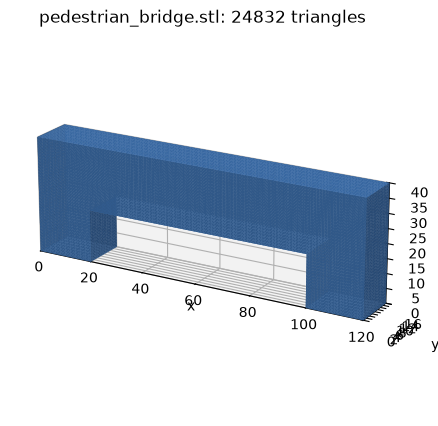

In [2]:
tri = read_stl(STL)
ax = plot_stl(tri, f"pedestrian_bridge.stl: {len(tri)} triangles")
ax.view_init(elev=20, azim=-60)
plt.show()

## 2. Voxelize: choose the resolution
Resolution = voxels along the longest side (120). At resolution 60 the voxel size is 2, which fits the
clearance (18 = 9 voxels) and abutments (20 = 10 voxels) exactly.

In [3]:
print(f"{'res':>4s} {'voxel size':>10s} {'grid':>14s} {'voxels':>7s} {'DOFs':>8s} {'volume error':>12s}")
for res in (30, 60, 120):
    m = VoxelMesh.from_stl(STL, resolution=res)
    i = m.info
    print(f"{res:4d} {i['voxel_size']:10.2f} {str(i['shape']):>14s} {i['n_voxels']:7d} {m.n_dof:8d} "
          f"{100 * (i['voxel_volume'] / i['stl_volume'] - 1):+11.2f}%")

mesh = VoxelMesh.from_stl(STL, resolution=60)
print("\nUsed:", mesh)

 res voxel size           grid  voxels     DOFs volume error
  30       4.00    (30, 4, 10)     800     3690       -4.76%
  60       2.00    (60, 8, 20)    6720    25110       +0.00%
 120       1.00  (120, 16, 40)   53760   180489       +0.00%

Used: VoxelMesh(grid 60 x 8 x 20, voxel [2.0, 2.0, 2.0], 6720 elements, 8370 nodes, 25110 DOFs)


## 3. Keep region, supports and load

deck (keep solid): 960 voxels = 14.3% of the domain
supports: 99 + 99 nodes, load on 549 deck nodes


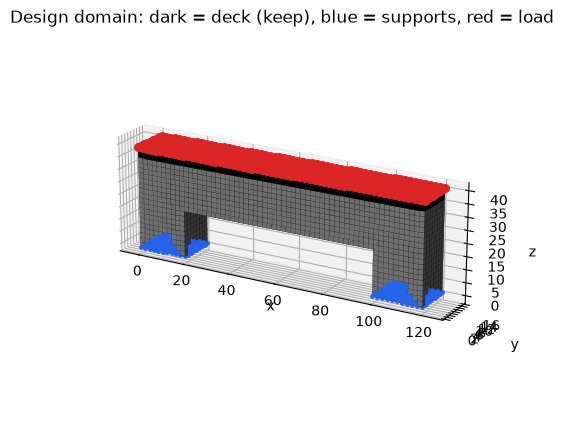

In [5]:
H, L = 40.0, 120.0
deck = np.nonzero(mesh.centers[:, 2] > 36)[0]                   # top 2 voxel layers
left_base = mesh.nodes_where(lambda x, y, z: (z < 1e-6) & (x <= 20 + 1e-6))
right_base = mesh.nodes_where(lambda x, y, z: (z < 1e-6) & (x >= 100 - 1e-6))
deck_top = mesh.nodes_where(lambda x, y, z: z > H - 1e-6)
print(f"deck (keep solid): {len(deck)} voxels = {len(deck) / mesh.n_elem:.1%} of the domain")
print(f"supports: {len(left_base)} + {len(right_base)} nodes, load on {len(deck_top)} deck nodes")


def make_bc(right_directions):
    bc = BoundaryConditions(mesh)
    bc.fix(left_base, "xyz")                    # pinned
    bc.fix(right_base, right_directions)        # "xyz" pinned, "yz" roller in x
    bc.load(deck_top, (0, 0, -1))               # uniform pedestrian load, total 1
    return bc


show = np.full(mesh.n_elem, 0.35)
show[deck] = 1.0
ax = plot_voxels(mesh, show, threshold=0.0, show_bcs=make_bc("xyz"),
                 title="Design domain: dark = deck (keep), blue = supports, red = load")
ax.view_init(elev=20, azim=-60)
plt.show()

## 4. Optimize both support cases

In [6]:
settings = TOSettings(volfrac=0.30, penal=3, rmin=1.5, max_iter=150)
cases = {"A: pinned - pinned": "xyz", "B: pinned - roller": "yz"}
results = {}
for name, dirs in cases.items():
    bc = make_bc(dirs)
    res = run_topopt(mesh, bc, settings, keep=deck)
    results[name] = (res, bc)
    print(f"{name}: converged = {res.converged}, {res.iterations} iterations, {res.time:.0f} s, "
          f"c = {res.compliance:.4f}, deck stays solid: {np.all(res.x[deck] == 1)}")
np.save("results/bridge_caseA_x.npy", results["A: pinned - pinned"][0].x)
np.save("results/bridge_caseB_x.npy", results["B: pinned - roller"][0].x)

A: pinned - pinned: converged = True, 80 iterations, 79 s, c = 0.6442, deck stays solid: True
B: pinned - roller: converged = True, 114 iterations, 247 s, c = 0.8459, deck stays solid: True


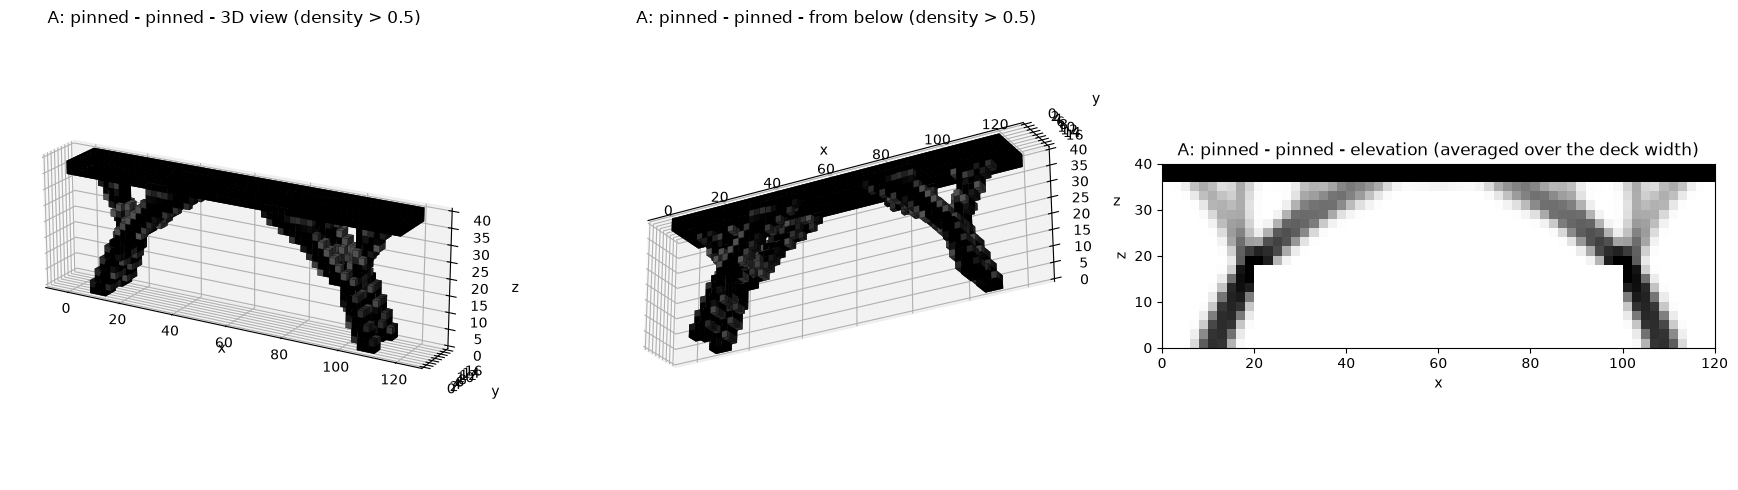

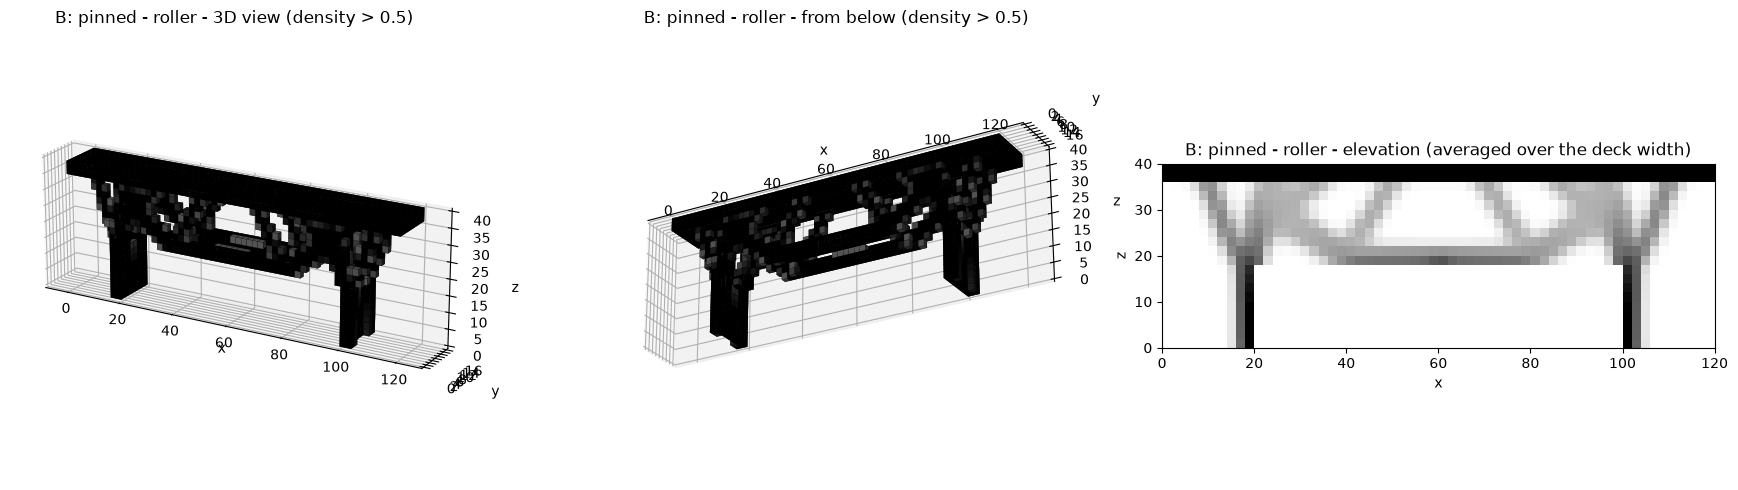

In [8]:
for name, (res, bc) in results.items():
    fig = plt.figure(figsize=(18, 5))
    for n, (elev, azim, label) in enumerate([(20, -60, "3D view"), (-25, -60, "from below")]):
        ax = fig.add_subplot(1, 3, n + 1, projection="3d")
        plot_voxels(mesh, res.x, threshold=0.5, ax=ax, title=f"{name} - {label} (density > 0.5)")
        ax.view_init(elev=elev, azim=azim)
    plot_side_view(mesh, res.x, f"{name} - elevation (averaged over the deck width)", fig.add_subplot(1, 3, 3), axis=1)
    plt.tight_layout(); plt.show()

## 5. Compare: stiffness and support reactions
Reactions from the final design: R = K u − f at the supported DOFs. The horizontal reaction is the
**thrust** that the abutments must resist.

case                   compliance   left Rx   left Rz  right Rx  right Rz
A: pinned - pinned         0.6442    +0.234    +0.500    -0.234    +0.500
B: pinned - roller         0.8459    +0.000    +0.500    -0.000    +0.500

Case B is 31% more flexible than case A (same amount of material).


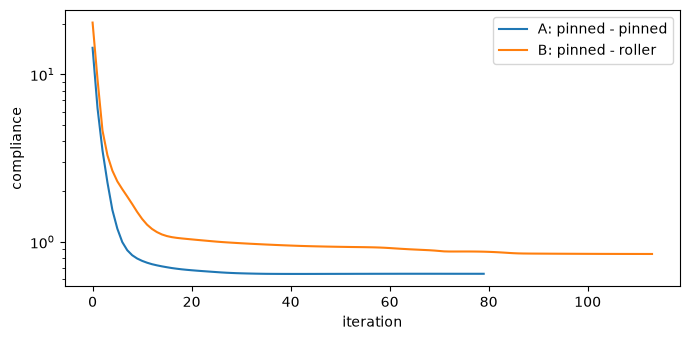

In [11]:
fe = FEModel(mesh, settings.E, settings.nu)
print(f"{'case':22s} {'compliance':>10s} {'left Rx':>9s} {'left Rz':>9s} {'right Rx':>9s} {'right Rz':>9s}")
for name, (res, bc) in results.items():
    R = fe.assemble(res.x, settings.penal) @ res.u - bc.forces
    Rx = lambda nodes: R[3 * nodes].sum()
    Rz = lambda nodes: R[3 * nodes + 2].sum()
    print(f"{name:22s} {res.compliance:10.4f} {Rx(left_base):+9.3f} {Rz(left_base):+9.3f} "
          f"{Rx(right_base):+9.3f} {Rz(right_base):+9.3f}")

cA = results["A: pinned - pinned"][0].compliance
cB = results["B: pinned - roller"][0].compliance
print(f"\nCase B is {100 * (cB / cA - 1):.0f}% more flexible than case A (same amount of material).")

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, (res, _) in results.items():
    ax.plot(res.history["c"], label=name)
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("compliance"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Discussion
- **A (pinned - pinned):** inclined legs lean out from the deck to the abutments, like the two halves of an arch.
  They push outward, and the pinned supports resist that push (horizontal thrust). A full arch cannot form because
  the clearance opening takes the space where it would be.
- **B (pinned - roller):** the roller cannot take a horizontal force, so the legs become vertical and a **tie**
  appears across the top of the opening: the structure carries the thrust internally (tied frame / truss).
- With the same material, the bridge with horizontally restrained supports is stiffer.
- The 3D views show what a 2D model cannot: how the material is distributed across the deck width.
- Limits: one load case (no unbalanced pedestrian load, no wind), no self-weight, linear isotropic material.